# Gene Subcellular Localization Analysis

In [78]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from collections import defaultdict, Counter
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
import umap
from functools import reduce
import operator
from adjustText import adjust_text
import harmonypy as hm
from pycytominer.feature_select import feature_select

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
from utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"
feat = "GFP"

## 1. Loading data

In [65]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
print("Number of hits:", imaging_summary_clinvar_hits.shape[0])
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())
hits_allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())
imaging_summary_clinvar.shape

gene_list = imaging_summary_clinvar.unique("Gene")["Gene"].to_list()
bio_reps = list(imaging_summary_clinvar["Metadata_Bio_Batch"].unique())

imaging_summary_clinvar_hits.head()

Number of hits: 178


Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,Gene_right,U2OS_cc_t_stat_right,U2OS_cc_t_pval_right,U2OS_prot_abun_t_stat_right,U2OS_prot_abun_t_pval_right,…,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,…,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,f64,f64,str,str
"""DCX""","""DCX_Arg59His""",-0.449045,0.666972,-11.028669,0.000011,"""2024_01_Batch_7-8""",true,false,false,false,false,false,false,false,false,false,0.946672,0.814316,0.871168,0.758391,0.534434,0.743842,0.873881,0.927511,0.845362,0.961282,0.325026,0.642902,0.814825,0.78327,0.932062,"""DCX""",-0.449045,0.666972,-11.028669,0.000011,…,1.11410223e8,"""Xq23""","""criteria provided, multiple su…",4.0,"""-""","""N""","""ClinGen:CA171866,UniProtKB:O43…",2.0,158433.0,1.11410223e8,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000192951|SCV002194037|SCV0…","""-""","""-""","""176G>A ""","""Arg59His""","""NM_001195553.2""",2.0,"""1_Pathogenic""",91.82,0.193548,"""['300067']""","""x-linked""","""Rare genetic developmental def…",2,"""LISSENCEPHALY, X-LINKED, 1""",91.82,0.193548,"""10-90""",""">90"""
"""MLH1""","""MLH1_Gly147Arg""",-0.464311,0.660844,4.60714,0.004136,"""2024_12_Batch_11-12""",true,true,true,true,false,true,true,false,false,false,0.985072,0.97017,0.959477,0.934237,0.902019,0.909733,0.951746,0.96911,0.968353,0.985722,0.894305,0.916729,0.949844,0.971986,0.984422,"""MLH1""",-0.464311,0.660844,4.60714,0.004136,…,3.7007049e7,"""3p22.2""","""criteria provided, conflicting…",4.0,"""ACMG2013,ACMG2016,ACMG2021,ACM…","""N""","""ClinGen:CA010397""",2.0,90218.0,3.7007049e7,"""G""","""C""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV001485207|SCV002052456|SCV0…","""-""","""-""","""439G>C ""","""Gly147Arg""","""NM_000249.4""",1.0,"""3_Conflicting""",96.19,0.047619,"""['609310']""","""autosomal dominant""","""Rare genetic immune disease; R…",3,"""LYNCH SYNDROME 2""",96.19,0.047619,"""<10""",""">90"""
"""AGXT""","""AGXT_Gly116Arg""",-3.209929,0.01486,-5.661659,0.000765,"""2024_01_Batch_7-8""",true,false,false,false,false,false,false,false,false,false,0.94447,0.706787,0.904016,0.830479,0.570044,0.651334,0.86228,0.911609,0.670866,0.951216,0.488755,0.798677,0.896423,0.742707,0.937723,"""AGXT""",-3.209929,0.01486,-5.661659,0.000765,…,2.4086935e8,"""2q37.3""","""criteri

## 2. Loading CellProfiler Features per Each Gene

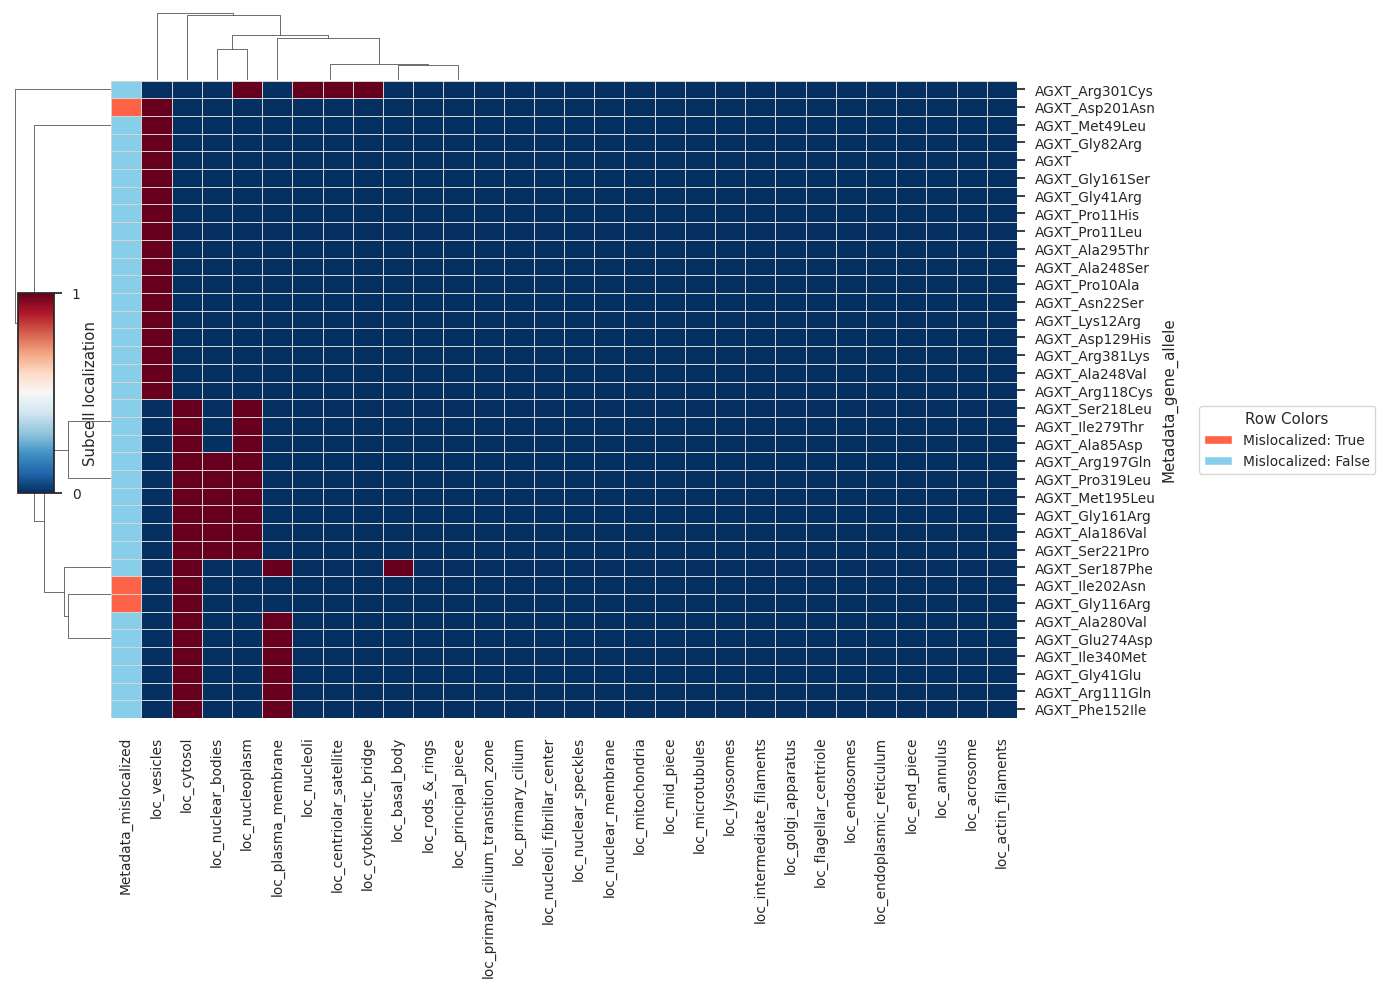

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import numpy as np
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

misloc_df = pl.read_csv("../../3_outputs/subcellular_localization_annotations.csv")
misloc_df = misloc_df.with_columns(
    pl.when(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_allele"].unique()))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("Metadata_mislocalized")
)

# Filter and prepare data
filtered_df = misloc_df.filter(
    pl.col("Metadata_gene_allele").str.contains("AGXT")
).to_pandas().set_index("Metadata_gene_allele")

# Extract the data for heatmap
heatmap_data = filtered_df[[c for c in misloc_df.columns if "loc_" in c]]

# Create row colors based on Metadata_mislocalized
row_colors = filtered_df["Metadata_mislocalized"].map({True: 'tomato', False: 'skyblue'})

# Create the clustermap
g = sns.clustermap(
    data=heatmap_data,
    cmap="RdBu_r",
    row_colors=row_colors,
    linewidths=0.5,
    linecolor="lightgrey",
    figsize=(12, 10),
    dendrogram_ratio=(0.1, 0.1),
    colors_ratio=0.03,
    vmin=0,  # Set min value to 0
    vmax=1,  # Set max value to 1
    cbar_kws={
        'ticks': [0, 1],  # Only show 0 and 1 on colorbar
        'shrink': 0.5,    # Make colorbar smaller
    }
)

# Add legend for row colors
legend_elements = [
    Patch(facecolor='tomato', label='Mislocalized: True'),
    Patch(facecolor='skyblue', label='Mislocalized: False')
]

g.ax_heatmap.legend(
    handles=legend_elements, 
    loc='upper left', 
    bbox_to_anchor=(1.2, .5),
    frameon=True,
    title='Row Colors'
)

# Move colorbar to center left
# First, remove the existing colorbar
g.cax.remove()

# Create new colorbar position (center left)
cbar_ax = g.fig.add_axes([0.02, 0.5, 0.03, 0.2])  # [left, bottom, width, height]
cbar = plt.colorbar(
    g.ax_heatmap.collections[0], 
    cax=cbar_ax,
    ticks=[0, 1]
)
cbar.set_label('Subcell localization', rotation=90, labelpad=2)
plt.show()

In [81]:
def analyze_mislocalization_patterns(df):
    """
    Analyze mislocalization patterns by comparing variant alleles to their reference genes
    """
    # Get location columns
    loc_cols = [col for col in df.columns if col.startswith('loc_')]
    print(f"Found {len(loc_cols)} location categories")
    
    # Separate reference genes and variants
    df['gene_name'] = df['Metadata_gene_allele'].apply(lambda x: x.split('_')[0] if '_' in x else x)
    df['is_reference'] = ~df['Metadata_gene_allele'].str.contains('_')
    
    reference_genes = df[df['is_reference']].copy()
    variant_alleles = df[~df['is_reference']].copy()
    
    print(f"Reference genes: {len(reference_genes)}")
    print(f"Variant alleles: {len(variant_alleles)}")
    
    # Create reference gene lookup
    ref_patterns = {}
    for _, row in reference_genes.iterrows():
        gene_name = row['gene_name']
        pattern = tuple(row[loc_cols].values)
        ref_patterns[gene_name] = pattern
    
    print(f"Found reference patterns for {len(ref_patterns)} genes")
    
    # Analyze variants
    mislocalization_data = []
    
    for _, variant in variant_alleles.iterrows():
        gene_name = variant['gene_name']
        variant_name = variant['Metadata_gene_allele']
        variant_pattern = tuple(variant[loc_cols].values)
        
        if gene_name in ref_patterns:
            ref_pattern = ref_patterns[gene_name]
            
            # Check if patterns differ
            has_mislocalization = variant_pattern != ref_pattern
            
            mislocalization_data.append({
                'gene': gene_name,
                'variant': variant_name,
                'has_mislocalization': has_mislocalization,
                'reference_pattern': ref_pattern,
                'variant_pattern': variant_pattern
            })
    
    return mislocalization_data, loc_cols
    

def calculate_pattern_changes(mislocalization_data, loc_cols):
    """
    Calculate unique pattern changes and their frequencies
    """
    # Count alleles with changes
    total_variants = len(mislocalization_data)
    changed_variants = sum(1 for item in mislocalization_data if item['has_mislocalization'])
    
    print(f"Total variants analyzed: {total_variants}")
    print(f"Variants with mislocalization: {changed_variants}")
    print(f"Percentage with changes: {changed_variants/total_variants*100:.1f}%")
    
    # Analyze pattern changes for variants with mislocalization
    pattern_changes = []
    
    for item in mislocalization_data:
        if item['has_mislocalization']:
            ref_pattern = np.array(item['reference_pattern'])
            var_pattern = np.array(item['variant_pattern'])
            
            # Calculate change vector (gained - lost locations)
            change_vector = var_pattern - ref_pattern
            
            # Create change description
            gained_locs = [loc_cols[i].replace('loc_', '') for i, val in enumerate(change_vector) if val > 0]
            lost_locs = [loc_cols[i].replace('loc_', '') for i, val in enumerate(change_vector) if val < 0]
            
            change_desc = {
                'variant': item['variant'],
                'gene': item['gene'],
                'gained': gained_locs,
                'lost': lost_locs,
                'change_vector': tuple(change_vector),
                'n_gained': len(gained_locs),
                'n_lost': len(lost_locs)
            }
            
            pattern_changes.append(change_desc)
    
    return pattern_changes


def summarize_unique_patterns(pattern_changes):
    """
    Find unique mislocalization patterns and their frequencies
    """
    # Group by change vector (unique patterns)
    pattern_counts = Counter(item['change_vector'] for item in pattern_changes)
    
    print(f"\nFound {len(pattern_counts)} unique mislocalization patterns")
    print(f"Top 10 most frequent patterns:")
    
    for i, (pattern, count) in enumerate(pattern_counts.most_common(10)):
        print(f"{i+1:2d}. Pattern occurs {count:3d} times: {pattern}")
    
    # Group by semantic changes (gained/lost combinations)
    semantic_changes = defaultdict(list)
    
    for change in pattern_changes:
        gained_str = ";".join(sorted(change['gained'])) if change['gained'] else "none"
        lost_str = ";".join(sorted(change['lost'])) if change['lost'] else "none"
        change_key = f"Gained: {gained_str} | Lost: {lost_str}"
        semantic_changes[change_key].append(change['variant'])
    
    print(f"\nSemantic change patterns:")
    for i, (change_desc, variants) in enumerate(sorted(semantic_changes.items(), key=lambda x: len(x[1]), reverse=True)[:15]):
        print(f"{i+1:2d}. {change_desc}")
        print(f"    Count: {len(variants)}, Examples: {', '.join(variants[:3])}")
        print()
    
    return pattern_counts, semantic_changes


# Main analysis
print("=== Mislocalization Pattern Analysis ===\n")

# Step 1: Load data and identify mislocalization
mislocalization_data, loc_cols = analyze_mislocalization_patterns(
    misloc_df.with_columns(
        pl.when(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_allele"].unique()))
        .then(pl.lit(True))
        .otherwise(pl.lit(False))
        .alias("Metadata_mislocalized")
    ).filter(
        (pl.col("Metadata_mislocalized")) | ~(pl.col("Metadata_gene_allele").str.contains('_'))
    ).to_pandas()
)

print("\n" + "="*50)

# Step 2: Analyze pattern changes
pattern_changes = calculate_pattern_changes(mislocalization_data, loc_cols)

print("\n" + "="*50)

# Step 3: Summarize unique patterns
pattern_counts, semantic_changes = summarize_unique_patterns(pattern_changes)

=== Mislocalization Pattern Analysis ===

Found 29 location categories
Reference genes: 129
Variant alleles: 178
Found reference patterns for 129 genes

Total variants analyzed: 178
Variants with mislocalization: 139
Percentage with changes: 78.1%


Found 91 unique mislocalization patterns
Top 10 most frequent patterns:
 1. Pattern occurs   7 times: (0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)
 2. Pattern occurs   6 times: (0.0, 0.0, 0.0, 1.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)
 3. Pattern occurs   6 times: (0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, -1.0)
 4. Pattern occurs   6 times: (0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 

In [76]:
# ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
# ref_var_cell_featsel_prof_df = pl.read_parquet(
#     "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_int_featselect.parquet"
# )
# feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

# # ref_var_cell_dr_embeddings_df = pl.read_parquet(
# #     "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_dr_embeddings.parquet"
# # ).with_columns(
# #     pl.col("Metadata_final_loc").str.to_lowercase().alias("Metadata_final_loc")
# # )

In [16]:
sig_diff_feat = list(set(list(feat_df["cp_feature"])).intersection(
    set([c for c in ref_var_cell_featsel_prof_df.columns if "Metadata" not in c])
))

gene_allele_feat_df = ref_var_cell_featsel_prof_df.group_by(
    "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well", "Metadata_hpa_main_loc" ## aggregate by well first
).agg(
    pl.col(col).mean().alias(col)
    for col in sig_diff_feat
).group_by(
    "Metadata_gene_allele", "Metadata_hpa_main_loc" ## aggregate by allele
).agg(
    pl.col(col).median().alias(col)
    for col in sig_diff_feat
)

# Extract features once
feature_cols = [c for c in gene_allele_feat_df.columns if "Metadata" not in c]
# features = ref_var_cell_all_prof_df.select(pl.col(feature_cols))

# Standardize by INT and fit PCA
data_scaled = inverse_normal_transform(gene_allele_feat_df, feature_cols)

data_scaled = feature_select(data_scaled.to_pandas(), operation="variance_threshold")
data_scaled = feature_select(data_scaled, operation="correlation_threshold")
data_scaled.shape

  0%|          | 0/129 [00:00<?, ?it/s]

(1007, 66)

In [19]:
data_scaled = pl.DataFrame(data_scaled)

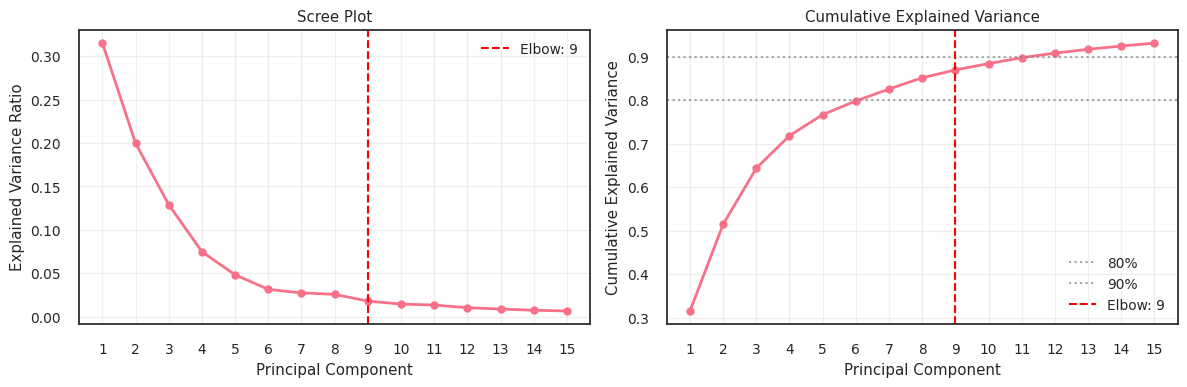

Optimal components: 9
Explained variance at elbow: 87.0%


In [20]:
# Fit PCA with all components
feature_cols = [c for c in data_scaled.columns if "Metadata" not in c]

pca_full = PCA()
pca_full.fit(data_scaled.select(feature_cols).to_numpy())

# Calculate variances
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

from kneed import KneeLocator
# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee

# explained_var_thres = 0.6
# cumvar = np.cumsum(pca_full.explained_variance_ratio_)
# optimal_components = np.argmax(cumvar >= explained_var_thres) + 1

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

# Apply optimal PCA
pca = PCA(n_components=optimal_components)
data_pca = pca.fit_transform(data_scaled.select(feature_cols).to_numpy())

In [21]:
# UMAP plot
reducer = umap.UMAP(n_components=2, random_state=42) ## metric='cosine', 
umap_embedding = reducer.fit_transform(data_pca)

In [24]:
# Generate k-NN graph
k = 15  # adjust based on testing
nbrs = NearestNeighbors(n_neighbors=k, metric='cosine')
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# Build unweighted graph
G = nx.Graph()
for i in range(len(data_pca)):
    for j in indices[i][1:]:  # skip self
        G.add_edge(i, j)

# Louvain clustering
cluster_dict = community_louvain.best_partition(G) # , resolution=2

In [31]:
dr_res_df = pd.DataFrame(
    data_pca,
    columns=[f"PC{i}" for i in range(1, data_pca.shape[1]+1)]
)
dr_res_df = pd.concat([
    dr_res_df,
    pd.DataFrame(umap_embedding, 
                 columns=["UMAP1", "UMAP2"])
    ],
    axis=1
)

dr_res_df["cluster"] = dr_res_df.index.map(cluster_dict)
dr_res_df.index = data_scaled["Metadata_gene_allele"]
dr_res_df["Metadata_hpa_main_loc"] = data_scaled["Metadata_hpa_main_loc"]

In [38]:
dr_res_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,UMAP1,UMAP2,cluster,Metadata_hpa_main_loc
GALE_Leu313Met,-1.873770,-4.303470,5.282035,0.070742,-1.275060,1.959928,1.096587,1.119851,-1.490457,-3.329885,10.814665,0,None
SMAD3_Tyr364Cys,1.255047,4.657368,6.462309,3.458669,-1.520909,0.220067,-0.977761,1.207320,1.685089,-6.003146,2.150923,2,None
MLH1_Ala681Thr,1.901694,5.381560,1.630186,-0.920286,-0.953884,-2.270113,1.263260,-0.088360,-1.984841,-2.613256,0.400451,3,None
KRT6A_Asn171Asp,-2.782726,0.804131,-0.951554,-0.283118,-0.739294,1.265707,1.280822,-0.853996,-1.668182,6.011241,8.314928,4,None
MVK_Thr209Ala,-2.466509,-4.942724,2.865126,-1.158165,-0.017737,-0.336649,1.164940,1.351306,0.063555,-3.162615,11.093383,0,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
SMAD3_Leu274Pro,7.811140,1.537432,1.080732,-0.057269,-2.139242,-0.397582,-1.340043,1.115430,-0.187544,-1.315858,3.786909,5,None
CTNNA3,7.501968,-2.364160,-0.104267,-1.370752,-0.729636,0.505330,-1.725228,0.313645,0.015615,-0.267855,3.970967,5,None
RPS19_Gly127Glu,2.873917,7.141837,0.439447,-2.035944,1.320553,-0.903112,0.503125,1.538394,-2.495095,-2.763064,0.527195,3,None
RAD51D_Val132Ile,4.057040,6.188360,1.920817,0.352666,1.000419,1.137730,2.436011,0.316760,0.431849,-3.614467,1.538580,9,None


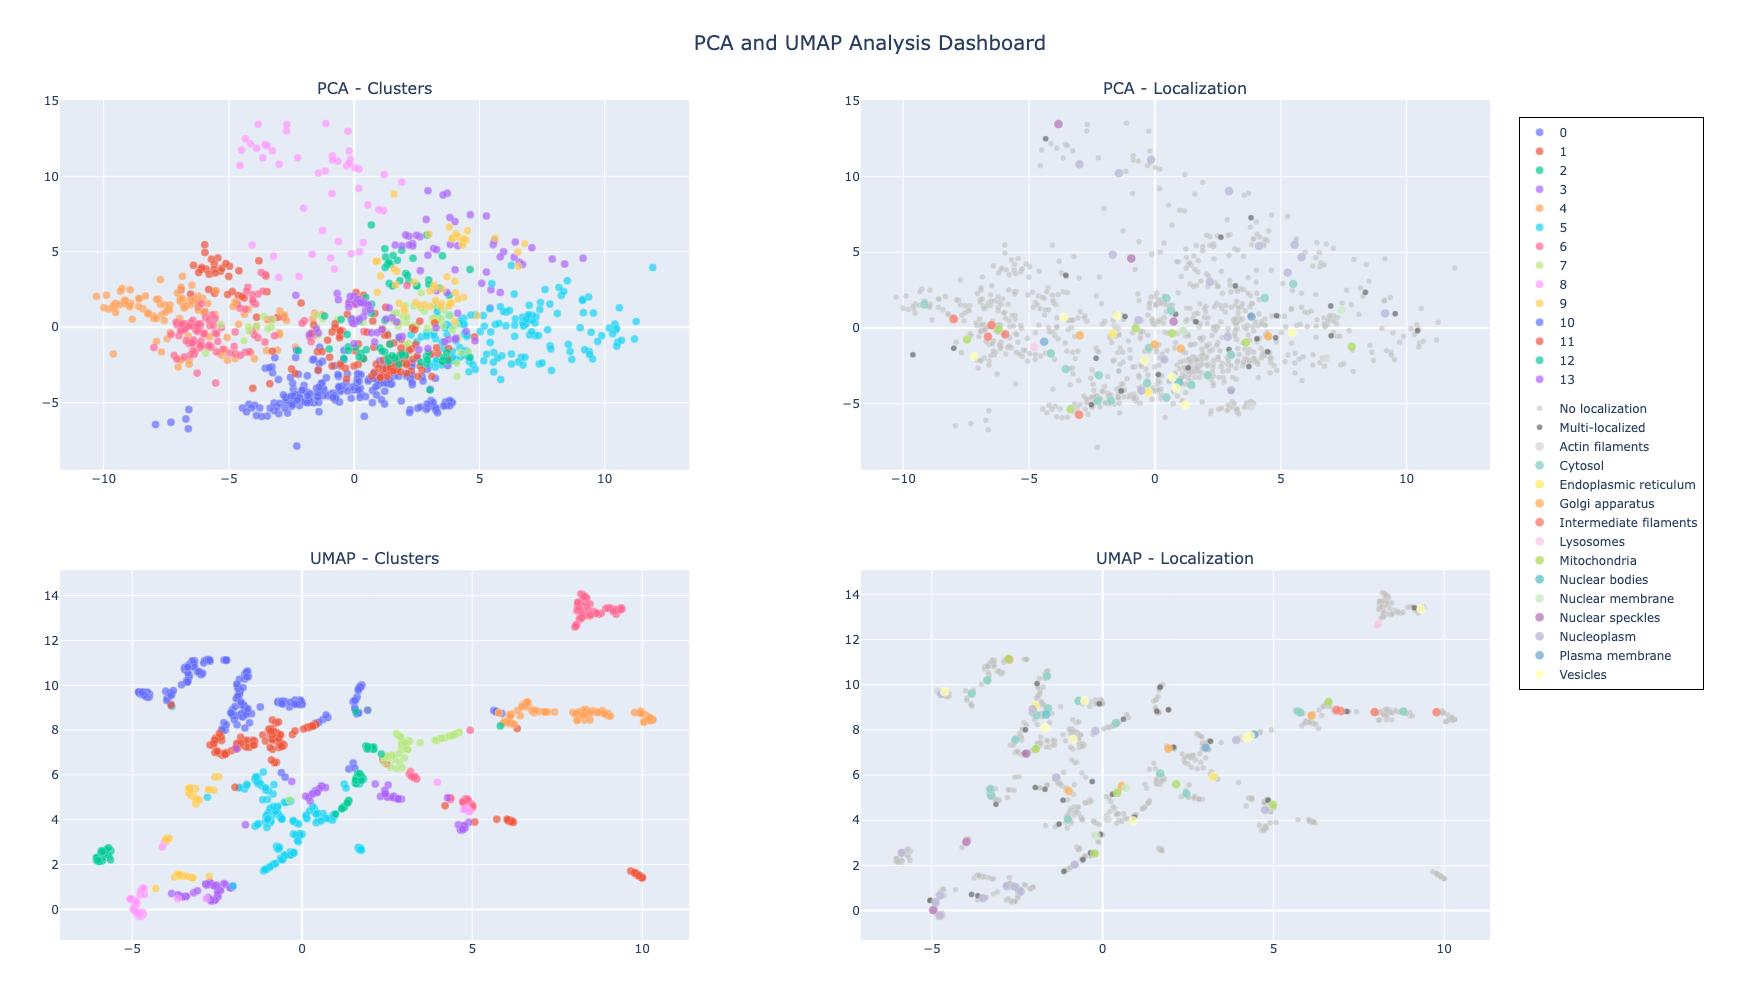


Dataset Summary:
Total genes: 1007
Clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


In [61]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
from plotly.subplots import make_subplots


def create_subplot_version(df):
   """Alternative: Create all plots in a single figure with subplots"""
   
   df = df.copy()
   df['localization_category'] = df['Metadata_hpa_main_loc'].apply(lambda x: 
       'No localization' if pd.isna(x) or x == 'None' else
       'Multi-localized' if ';' in str(x) else
       str(x)
   )
   
   # Create subplots with custom spacing
   fig = make_subplots(
       rows=2, cols=2,
       subplot_titles=('PCA - Clusters', 'PCA - Localization', 
                      'UMAP - Clusters', 'UMAP - Localization'),
       horizontal_spacing=0.12,
       vertical_spacing=0.12
   )
   
   # Color schemes
   unique_locs = [loc for loc in df['localization_category'].unique() 
                  if loc not in ['No localization', 'Multi-localized']]
   colors = px.colors.qualitative.Set3 + px.colors.qualitative.Pastel + px.colors.qualitative.Set1
   loc_colors = {loc: colors[i % len(colors)] for i, loc in enumerate(unique_locs)}
   loc_colors['No localization'] = '#C0C0C0'  # Darker light grey
   loc_colors['Multi-localized'] = '#505050'  # Dark grey
   
   # Plot configurations
   plots_config = [
       ('PC1', 'PC2', 'cluster', 1, 1, None, 'Cluster'),
       ('PC1', 'PC2', 'localization_category', 1, 2, loc_colors, 'Localization'),
       ('UMAP1', 'UMAP2', 'cluster', 2, 1, None, 'Cluster'),
       ('UMAP1', 'UMAP2', 'localization_category', 2, 2, loc_colors, 'Localization')
   ]
   
   for x_col, y_col, color_by, row, col, color_map, legend_prefix in plots_config:
       if color_by == 'localization_category':
           # Plot background categories first, then specific localizations
           background_categories = ['No localization', 'Multi-localized']
           specific_categories = [cat for cat in sorted(df[color_by].unique()) 
                                if cat not in background_categories]
           plot_order = background_categories + specific_categories
       else:
           plot_order = sorted(df[color_by].unique())
       
       for i, value in enumerate(plot_order):
           if value not in df[color_by].values:
               continue
               
           subset = df[df[color_by] == value]
           
           if color_map:
               color = color_map.get(value, '#000000')
               # Make background categories less prominent but still visible
               if value in ['No localization', 'Multi-localized']:
                   opacity = 0.6  # Increased from 0.4
                   size = 6  # Increased from 5
               else:
                   opacity = 0.8
                   size = 9  # Increased from 7
           else:
               color_idx = i % len(px.colors.qualitative.Plotly)
               color = px.colors.qualitative.Plotly[color_idx]
               opacity = 0.7
               size = 8  # Increased from 7
           
           # Create legend group name
           legend_group = f'{legend_prefix}_{row}_{col}'
           show_legend = (row == 1)  # Only show legend for top row
           
           fig.add_trace(
               go.Scatter(
                   x=subset[x_col],
                   y=subset[y_col],
                   mode='markers',
                   name=str(value),
                   legendgroup=legend_group,
                   showlegend=show_legend,
                   marker=dict(
                       color=color, 
                       size=size, 
                       opacity=opacity,
                       line=dict(width=0.3, color='white')
                   ),
                   customdata=np.column_stack((
                       subset.index,
                       subset['cluster'],
                       subset['Metadata_hpa_main_loc'].fillna('None')
                   )),
                   hovertemplate='<b>%{customdata[0]}</b><br>' +
                                f'{x_col}: %{{x:.3f}}<br>' +
                                f'{y_col}: %{{y:.3f}}<br>' +
                                'Cluster: %{customdata[1]}<br>' +
                                'Localization: %{customdata[2]}<br>' +
                                '<extra></extra>'
               ),
               row=row, col=col
           )
   
   # Update subplot titles with larger font
   for i, annotation in enumerate(fig['layout']['annotations']):
       annotation['font'] = dict(size=16)
   
   fig.update_layout(
       title=dict(
           text='PCA and UMAP Analysis Dashboard',
           font=dict(size=20),
           x=0.5
       ),
       height=1000,
       width=1400,
       legend=dict(
           font=dict(size=12),
           yanchor="top",
           y=0.98,
           xanchor="left",
           x=1.02,
           bgcolor="rgba(255,255,255,0.8)",
           bordercolor="Black",
           borderwidth=1
       ),
       margin=dict(l=60, r=250, t=100, b=60)
   )
   
   # Update axis labels
   fig.update_xaxes(title_font=dict(size=14), tickfont=dict(size=12))
   fig.update_yaxes(title_font=dict(size=14), tickfont=dict(size=12))
   
   return fig

# Usage

# # Option 2: Combined subplot dashboard (larger size)
# print("Creating combined dashboard...")
dashboard = create_subplot_version(df)
dashboard.show()

# Option 3: Show summary statistics
print("\nDataset Summary:")
print(f"Total genes: {len(df)}")
print(f"Clusters: {sorted(df['cluster'].unique())}")
# print(f"Localization patterns: {df[''].value_counts()}")

In [60]:
df[["cluster","Metadata_hpa_main_loc","PC1"]].groupby(["cluster","Metadata_hpa_main_loc"]).count().to_dict()

{'PC1': {(0, 'Cytosol'): 4,
  (0, 'Cytosol;Golgi apparatus'): 1,
  (0, 'Cytosol;Plasma membrane'): 1,
  (0, 'Cytosol;Vesicles'): 1,
  (0, 'Endoplasmic reticulum'): 1,
  (0, 'Intermediate filaments'): 1,
  (0, 'Mitochondria'): 1,
  (0, 'Nuclear bodies'): 1,
  (0, 'Nucleoplasm'): 1,
  (0, 'Vesicles'): 1,
  (2, 'Cytosol'): 1,
  (2, 'Nucleoplasm'): 1,
  (3, 'Nuclear bodies;Nucleoplasm'): 1,
  (3, 'Nucleoli;Nucleoplasm'): 1,
  (3, 'Nucleoplasm'): 5,
  (4, 'Cytosol'): 2,
  (4, 'Cytosol;Nucleoplasm'): 1,
  (4, 'Golgi apparatus'): 1,
  (4, 'Intermediate filaments'): 4,
  (4, 'Mitochondria'): 1,
  (5, 'Actin filaments'): 1,
  (5, 'Cytosol'): 1,
  (5, 'Cytosol;Microtubules'): 1,
  (5, 'Cytosol;Nucleoplasm'): 2,
  (5, 'Cytosol;Plasma membrane'): 2,
  (5, 'Golgi apparatus'): 1,
  (5, 'Mitochondria'): 1,
  (5, 'Nuclear bodies;Nucleoplasm'): 1,
  (5, 'Nuclear membrane'): 1,
  (5, 'Nuclear membrane;Nucleoplasm'): 1,
  (5, 'Nucleoplasm'): 2,
  (5, 'Nucleoplasm;Vesicles'): 1,
  (5, 'Vesicles'): 1,
  (6

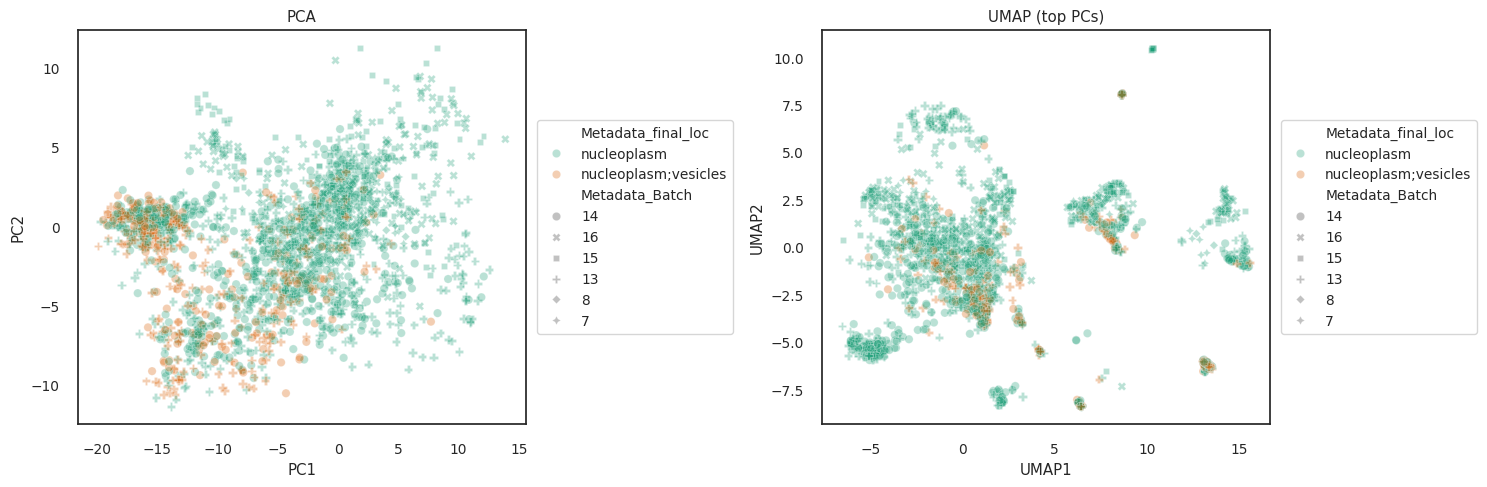

In [142]:
# Plot side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(
    data=ref_var_cell_dr_embeddings_df.filter(
        ~pl.col("Metadata_gene_allele").str.contains("_"),
        pl.col("Metadata_final_loc").str.to_lowercase().str.starts_with("nucleoplasm")
    ).sample(fraction=0.1, seed=0).to_pandas(),
    x="PC1",
    y="PC2",
    hue="Metadata_final_loc",
    style="Metadata_Batch",
    palette="Dark2",
    ax=ax1,
    alpha=.3
)
# PCA plot
# scatter1 = ax1.scatter(data_results['PC1'], data_results['PC2'], 
#                      c=data_results['Metadata_Batch'].astype(int), cmap='tab10', alpha=0.6)
# ax1.set_xlabel('PC1')
# ax1.set_ylabel('PC2')
ax1.set_title('PCA')
ax1.legend(bbox_to_anchor=(1.01, 0.5), loc='center left', 
           frameon=True, title="", ncol=1)
# ax1.get_legend().remove()


# UMAP plot
sns.scatterplot(
    data=ref_var_cell_dr_embeddings_df.filter(
        ~pl.col("Metadata_gene_allele").str.contains("_"),
        pl.col("Metadata_final_loc").str.to_lowercase().str.starts_with("nucleoplasm")
    ).sample(fraction=0.1, seed=0).to_pandas(),
    x="UMAP1",
    y="UMAP2",
    style="Metadata_Batch",
    hue="Metadata_final_loc",
    palette="Dark2",
    ax=ax2,
    alpha=.3
)
ax2.set_title('UMAP (top PCs)')
ax2.legend(bbox_to_anchor=(1.01, 0.5), loc='center left', 
           frameon=True, title="", ncol=1)
plt.subplots_adjust(wspace=0.3)
plt.tight_layout()
plt.show()

In [137]:
ref_var_cell_dr_embeddings_df.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_"),
    pl.col("Metadata_final_loc").str.to_lowercase().str.starts_with("nucleoplasm")
).unique(subset=["Metadata_final_loc", "Metadata_gene_allele"])

PC1,PC2,UMAP1,UMAP2,Metadata_CellID,Metadata_Batch,Metadata_final_loc,Metadata_gene_allele
f32,f32,f32,f32,str,str,str,str
-4.002081,-1.429058,-0.056839,-2.872904,"""2025_01_27_B13A7A8P2_T1_M04_26…","""13""","""nucleoplasm;vesicles""","""SOS2"""
1.556211,3.317701,-4.295095,-0.641799,"""2025_01_27_B13A7A8P1_T1_B23_41…","""13""","""nucleoplasm""","""SHOC2"""
-0.67874,-1.825346,-0.036903,-1.518877,"""2024_01_19_B7A1R1_P4T1_J17_209…","""7""","""nucleoplasm""","""WRAP53"""
9.703111,-3.009718,0.436176,6.167876,"""2025_01_27_B13A7A8P1_T1_A05_45…","""13""","""nucleoplasm""","""BCL10"""
3.583011,-1.940947,-5.839766,-4.988413,"""2025_01_27_B13A7A8P1_T1_I02_17…","""13""","""nucleoplasm""","""CTCF"""
4.499197,4.050032,-3.392649,2.029185,"""2025-03-17_B15A1A2_P1T1_F21_12…","""15""","""nucleoplasm""","""SMARCB1"""


In [43]:
# Analyze batch correlation
from scipy.stats import f_oneway
pc1_groups = [data_results[data_results['Metadata_Batch'] == batch]['PC1'] for batch in data_results['Metadata_Batch'].unique()]
pc2_groups = [data_results[data_results['Metadata_Batch'] == batch]['PC2'] for batch in data_results['Metadata_Batch'].unique()]
umap1_groups = [data_results[data_results['Metadata_Batch'] == batch]['UMAP1'] for batch in data_results['Metadata_Batch'].unique()]
umap2_groups = [data_results[data_results['Metadata_Batch'] == batch]['UMAP2'] for batch in data_results['Metadata_Batch'].unique()]

f_stat_pc1, p_val_pc1 = f_oneway(*pc1_groups)
f_stat_pc2, p_val_pc2 = f_oneway(*pc2_groups)
f_stat_umap1, p_val_umap1 = f_oneway(*umap1_groups)
f_stat_umap2, p_val_umap2 = f_oneway(*umap2_groups)

print(f"PC1 batch effect: F={f_stat_pc1:.3f}, p={p_val_pc1:.3e}")
print(f"PC2 batch effect: F={f_stat_pc2:.3f}, p={p_val_pc2:.3e}")
print(f"UMAP1 batch effect: F={f_stat_umap1:.3f}, p={p_val_umap1:.3e}")
print(f"UMAP2 batch effect: F={f_stat_umap2:.3f}, p={p_val_umap2:.3e}")

PC1 batch effect: F=4136.570, p=0.000e+00
PC2 batch effect: F=937.819, p=0.000e+00
UMAP1 batch effect: F=3468.621, p=0.000e+00
UMAP2 batch effect: F=1302.067, p=0.000e+00


In [63]:
df_results_w_loc = pd.DataFrame()
for name, group in data_results[(data_results["Metadata_final_loc"]!="Uncertain")&(~data_results["Metadata_final_loc"].isnull())].groupby(["Metadata_final_loc","Metadata_gene_allele"]):
    df_results_w_loc = pd.concat([df_results_w_loc, 
                                  group.sample(frac=20 / group.shape[0])])

In [48]:
# ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
#     pl.col("Metadata_Plate")
#       # capture a “B” followed by any non-underscore chars up to the first “A”
#       .str.extract(r"(B[^_]*?A)", 1)
#       .alias("Metadata_Batch")
# ).with_columns(
#     pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
# )

# ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
#     "Metadata_Plate", "Metadata_Well", "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).group_by(
#     "Metadata_gene_allele", "Metadata_Bio_Batch" #
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"]) ## 

# non_null_cols_batch = [col for col in ref_var_allele_batch_all_prof_df.columns if not ref_var_allele_batch_all_prof_df[col].is_null().any() and "Metadata" not in col]
# var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
# ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
#     var_allele_meta_cols+non_null_cols_batch
# )

In [49]:
# ref_var_allele_batch_all_prof_df.write_csv("../../3_outputs/agg_gene_batch_cp_profiles.csv")

### 2.2 Loading Gene CP profiles

In [169]:
ref_var_allele_batch_all_prof_df = pl.read_csv("../../3_outputs/agg_gene_batch_cp_profiles.csv")

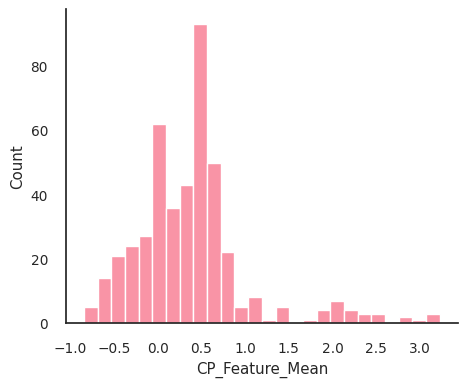

In [170]:
sns.displot(
    x=ref_var_allele_batch_all_prof_df.select(
        pl.col([c for c in ref_var_allele_batch_all_prof_df.columns if "Meta" not in c])
    ).mean().transpose(include_header=True).rename({"column_0": "CP_Feature_Mean"})["CP_Feature_Mean"],
    height=4, aspect=1.2
)

In [171]:
from utils import *
## normalize the features
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_all_prof_df)
## remove corr features
ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_proc_prof_df, corr_thres=0.9)

Computing UMAP embedding...


<Axes: xlabel='UMAP1', ylabel='UMAP2'>

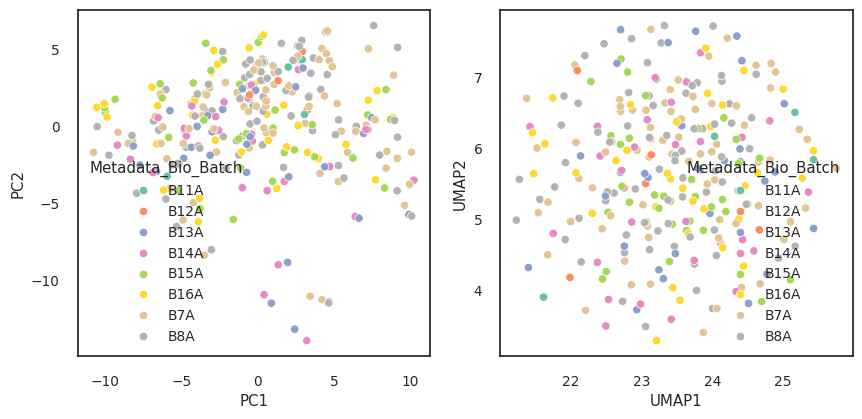

In [172]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
umap_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
pca_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Metadata_Bio_Batch", palette="Set2", ax=axes[0],
                hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_Bio_Batch", palette="Set2",  ax=axes[1],
               hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))

__No significant batch effects detected, aggregate the CP profiles to allele level across batches.__

### 2.4 Agg to allele

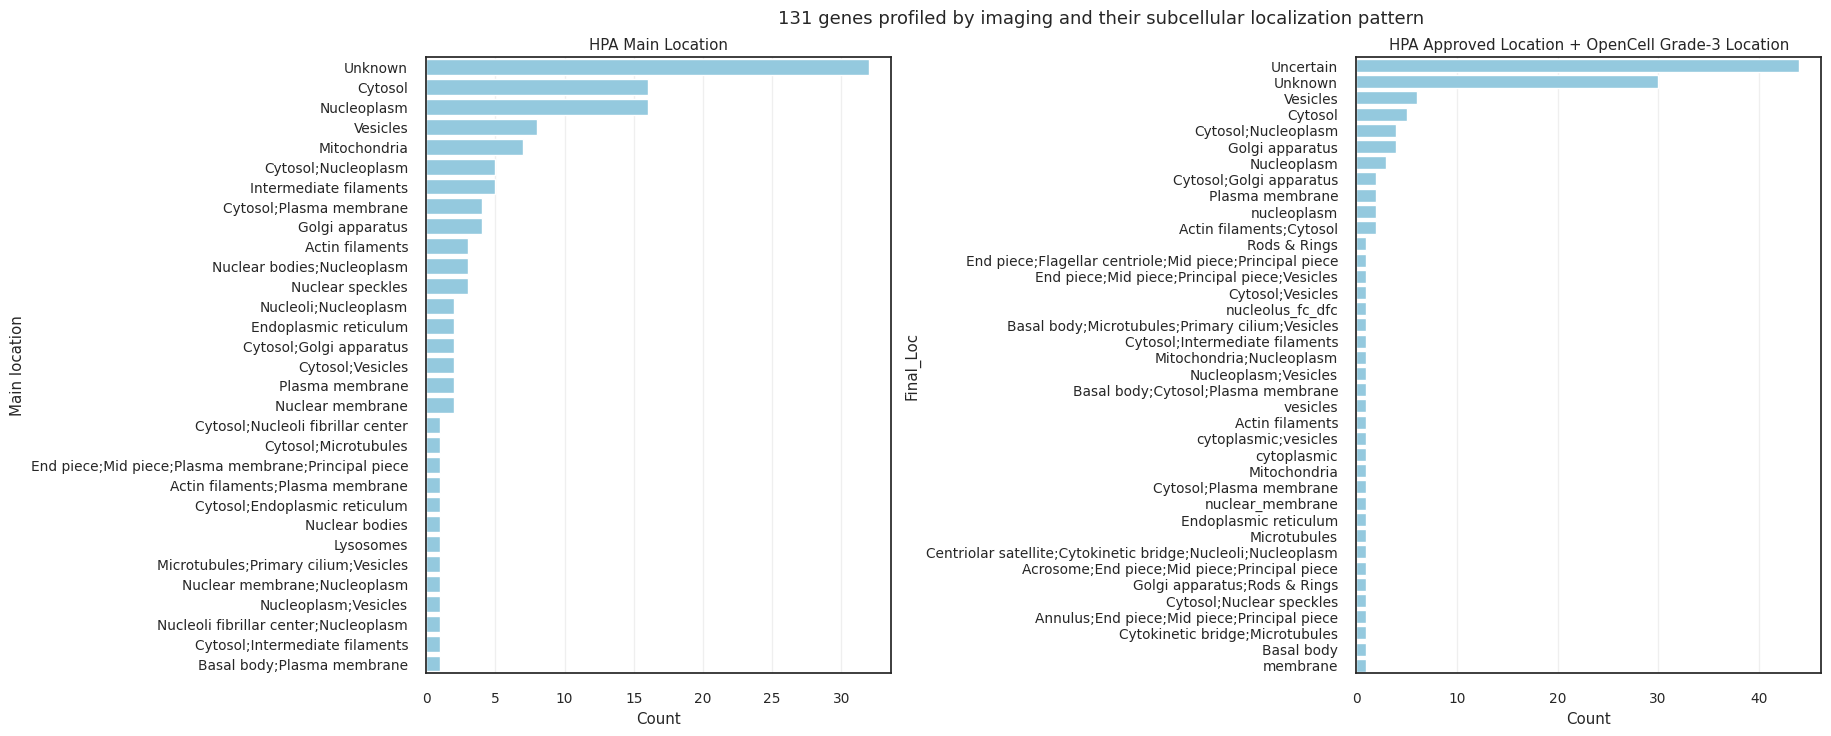

In [174]:
fig, axes = plt.subplots(1,2,figsize=(18, 8))
sns.barplot(
    data=ref_batch_proc_prof_loc_df.group_by("Main location").agg(pl.len()).rename({"len": "Count"}),
    x="Count",
    y="Main location",
    ax=axes[0],
    order=ref_batch_proc_prof_loc_df.group_by("Main location").agg(pl.len()).rename({"len": "Count"}).sort("Count", descending=True)["Main location"],
    color="skyblue"
)
sns.barplot(
    data=ref_batch_proc_prof_loc_df.group_by("Final_Loc").agg(pl.len()).rename({"len": "Count"}),
    x="Count",
    y="Final_Loc",
    ax=axes[1],
    order=ref_batch_proc_prof_loc_df.group_by("Final_Loc").agg(pl.len()).rename({"len": "Count"}).sort("Count", descending=True)["Final_Loc"],
    color="skyblue"
)
axes[0].grid(axis="x", alpha=.3)
axes[0].set_title("HPA Main Location")

axes[1].grid(axis="x", alpha=.3)
axes[1].set_title("HPA Approved Location + OpenCell Grade-3 Location")

plt.suptitle(f"{ref_batch_proc_prof_loc_df.shape[0]} genes profiled by imaging and their subcellular localization pattern", y=.94)
plt.subplots_adjust(wspace=1.)
custom_palette = sns.color_palette("colorblind", 10) + \
                 sns.color_palette("Set2", 8) + \
                 sns.color_palette("Dark2", 8) + \
                 sns.color_palette("Pastel1", 9)